### Required Assignment 5.1: Will the Customer Accept the Coupon?

**Context**

Imagine driving through town and a coupon is delivered to your cell phone for a restaurant near where you are driving. Would you accept that coupon and take a short detour to the restaurant? Would you accept the coupon but use it on a subsequent trip? Would you ignore the coupon entirely? What if the coupon was for a bar instead of a restaurant? What about a coffee house? Would you accept a bar coupon with a minor passenger in the car? What about if it was just you and your partner in the car? Would weather impact the rate of acceptance? What about the time of day?

Obviously, proximity to the business is a factor on whether the coupon is delivered to the driver or not, but what are the factors that determine whether a driver accepts the coupon once it is delivered to them? How would you determine whether a driver is likely to accept a coupon?

**Overview**

The goal of this project is to use what you know about visualizations and probability distributions to distinguish between customers who accepted a driving coupon versus those that did not.

**Data**

This data comes to us from the UCI Machine Learning repository and was collected via a survey on Amazon Mechanical Turk. The survey describes different driving scenarios including the destination, current time, weather, passenger, etc., and then ask the person whether he will accept the coupon if he is the driver. Answers that the user will drive there ‘right away’ or ‘later before the coupon expires’ are labeled as ‘Y = 1’ and answers ‘no, I do not want the coupon’ are labeled as ‘Y = 0’.  There are five different types of coupons -- less expensive restaurants (under \$20), coffee houses, carry out & take away, bar, and more expensive restaurants (\$20 - $50).

**Deliverables**

Your final product should be a brief report that highlights the differences between customers who did and did not accept the coupons.  To explore the data you will utilize your knowledge of plotting, statistical summaries, and visualization using Python. You will publish your findings in a public facing github repository as your first portfolio piece.





### Data Description
Keep in mind that these values mentioned below are average values.

The attributes of this data set include:
1. User attributes
    -  Gender: male, female
    -  Age: below 21, 21 to 25, 26 to 30, etc.
    -  Marital Status: single, married partner, unmarried partner, or widowed
    -  Number of children: 0, 1, or more than 1
    -  Education: high school, bachelors degree, associates degree, or graduate degree
    -  Occupation: architecture & engineering, business & financial, etc.
    -  Annual income: less than \\$12500, \\$12500 - \\$24999, \\$25000 - \\$37499, etc.
    -  Number of times that he/she goes to a bar: 0, less than 1, 1 to 3, 4 to 8 or greater than 8
    -  Number of times that he/she buys takeaway food: 0, less than 1, 1 to 3, 4 to 8 or greater
    than 8
    -  Number of times that he/she goes to a coffee house: 0, less than 1, 1 to 3, 4 to 8 or
    greater than 8
    -  Number of times that he/she eats at a restaurant with average expense less than \\$20 per
    person: 0, less than 1, 1 to 3, 4 to 8 or greater than 8
    -  Number of times that he/she goes to a bar: 0, less than 1, 1 to 3, 4 to 8 or greater than 8
    

2. Contextual attributes
    - Driving destination: home, work, or no urgent destination
    - Location of user, coupon and destination: we provide a map to show the geographical
    location of the user, destination, and the venue, and we mark the distance between each
    two places with time of driving. The user can see whether the venue is in the same
    direction as the destination.
    - Weather: sunny, rainy, or snowy
    - Temperature: 30F, 55F, or 80F
    - Time: 10AM, 2PM, or 6PM
    - Passenger: alone, partner, kid(s), or friend(s)


3. Coupon attributes
    - time before it expires: 2 hours or one day

In [2]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

### Problems

Use the prompts below to get started with your data analysis.  

1. Read in the `coupons.csv` file.




In [4]:
data = pd.read_csv('data/coupons.csv')

In [5]:
data.head()

,destination,passanger,weather,temperature,time,coupon,expiration,gender,age,maritalStatus,...,CoffeeHouse,CarryAway,RestaurantLessThan20,Restaurant20To50,toCoupon_GEQ5min,toCoupon_GEQ15min,toCoupon_GEQ25min,direction_same,direction_opp,Y
0,No Urgent Place,Alone,Sunny,55,2PM,Restaurant(<20),1d,Female,21,Unmarried partner,...,never,NaN,4~8,1~3,1,0,0,0,1,1
1,No Urgent Place,Friend(s),Sunny,80,10AM,Coffee House,2h,Female,21,Unmarried partner,...,never,NaN,4~8,1~3,1,0,0,0,1,0
2,No Urgent Place,Friend(s),Sunny,80,10AM,Carry out & Take away,2h,Female,21,Unmarried partner,...,never,NaN,4~8,1~3,1,1,0,0,1,1
3,No Urgent Place,Friend(s),Sunny,80,2PM,Coffee House,2h,Female,21,Unmarried partner,...,never,NaN,4~8,1~3,1,1,0,0,1,0
4,No Urgent Place,Friend(s),Sunny,80,2PM,Coffee House,1d,Female,21,Unmarried partner,...,never,NaN,4~8,1~3,1,1,0,0,1,0


2. Investigate the dataset for missing or problematic data.

In [6]:
## Overview of Columns, Data Types, and Non-Null Counts
data.info()

## Count Missing Values per Column
missing = data.isnull().sum()
missing_pct = (missing / len(data) * 100).round(2)
pd.DataFrame({'missing': missing, 'percent': missing_pct}).query('missing > 0').sort_values('missing', ascending=False)

## Check for Duplicate Rows
data.duplicated().sum()

## Look at the Unique Values in Each Text Column to Spot Odd Entries
for col in data.select_dtypes(include='object').columns:
    print(col, data[col].unique())

## Look for columns that never change
data.nunique().sort_values()

## Publish Results
missing = missing[missing > 0].sort_values(ascending=False)

missing_table = pd.DataFrame({
    'Column': missing.index,
    'Missing': missing.values,
    'Percent': (missing.values / len(data) * 100).round(1)
})

missing_table['Missing'] = missing_table.apply(
    lambda r: f"{r['Missing']:,} of {len(data):,} ({r['Percent']}%)", axis=1
)

missing_table = missing_table[['Column', 'Missing']]
missing_table.style.hide(axis='index')

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12684 entries, 0 to 12683
Data columns (total 26 columns):
 #   Column                Non-Null Count  Dtype 
---  ------                --------------  ----- 
 0   destination           12684 non-null  object
 1   passanger             12684 non-null  object
 2   weather               12684 non-null  object
 3   temperature           12684 non-null  int64 
 4   time                  12684 non-null  object
 5   coupon                12684 non-null  object
 6   expiration            12684 non-null  object
 7   gender                12684 non-null  object
 8   age                   12684 non-null  object
 9   maritalStatus         12684 non-null  object
 10  has_children          12684 non-null  int64 
 11  education             12684 non-null  object
 12  occupation            12684 non-null  object
 13  income                12684 non-null  object
 14  car                   108 non-null    object
 15  Bar                   12577 non-null

Column,Missing
car,"12,576 of 12,684 (99.1%)"
CoffeeHouse,"217 of 12,684 (1.7%)"
Restaurant20To50,"189 of 12,684 (1.5%)"
CarryAway,"151 of 12,684 (1.2%)"
RestaurantLessThan20,"130 of 12,684 (1.0%)"
Bar,"107 of 12,684 (0.8%)"


3. Decide what to do about your missing data -- drop, replace, other...

In [8]:
"""
Problem 3: Decide what to do about missing data -- drop, replace, other.
Dataset: coupons.csv (12,684 rows x 26 columns)

What's missing:
  car                   12,576  (99.15%)
  CoffeeHouse              217  (1.71%)
  Restaurant20To50         189  (1.49%)
  CarryAway                151  (1.19%)
  RestaurantLessThan20     130  (1.02%)
  Bar                      107  (0.84%)
  Everything else (including the target Y) is complete.

Decisions:
  1. DROP the `car` column. With 99% missing there is nothing to learn
     from it, and filling it would mean inventing almost the whole column.
  2. REPLACE gaps in the five frequency columns (Bar, CoffeeHouse,
     CarryAway, RestaurantLessThan20, Restaurant20To50) with each column's
     most common answer (mode). Why:
       - Only 605 rows (4.8%) have any gap, and each column is < 2% missing.
       - They are categorical survey answers ("never", "less1", "1~3", ...),
         so mean/median don't apply; the mode is the natural fill.
       - Rows with gaps accept coupons at about the same rate as the rest
         (55.0% vs 56.9%), so the missingness looks random and filling
         keeps those rows' other 24 columns of information.
  Alternative: dropping the 605 incomplete rows would also be defensible
  (see DROP_ROWS_INSTEAD below) since it only loses 4.8% of the data.
"""

import pandas as pd

TARGET = "Y"
DROP_ROWS_INSTEAD = False   # True = drop incomplete rows instead of filling

FREQ_COLS = ["Bar", "CoffeeHouse", "CarryAway",
             "RestaurantLessThan20", "Restaurant20To50"]

df = data.copy()
print(f"Starting from 'data': {df.shape[0]:,} rows x {df.shape[1]} columns\n")

# --- Inspect -------------------------------------------------------------
missing = df.isna().sum()
missing = missing[missing > 0].sort_values(ascending=False)
print("Missing values before cleaning:")
print(pd.DataFrame({"n_missing": missing,
                    "pct": (missing / len(df) * 100).round(2)}), "\n")

# Is missingness related to the target? (if so, it would be worth flagging)
has_gap = df[FREQ_COLS].isna().any(axis=1)
print(f"Rows with any frequency gap: {has_gap.sum()} ({has_gap.mean():.1%})")
print(f"Coupon acceptance (Y) -- rows with gaps: {df.loc[has_gap, TARGET].mean():.1%}, "
      f"complete rows: {df.loc[~has_gap, TARGET].mean():.1%}\n")

# --- 1. Drop the nearly empty column -----------------------------------
df = df.drop(columns=["car"])
print("Dropped column 'car' (99% missing)")

# --- 2. Replace (or drop) the frequency-column gaps ------------------------
if DROP_ROWS_INSTEAD:
    before = len(df)
    df = df.dropna(subset=FREQ_COLS)
    print(f"Dropped {before - len(df)} rows with missing frequency answers")
else:
    for col in FREQ_COLS:
        mode = df[col].mode()[0]
        n = df[col].isna().sum()
        df[col] = df[col].fillna(mode)
        print(f"Filled {n:>3} gaps in {col:<21} with mode '{mode}'")

# --- Verify --------------------------------------------------------------
remaining = int(df.isna().sum().sum())
assert remaining == 0, f"{remaining} missing values remain"
print(f"\nRemaining missing values: {remaining}")
print(f"Final shape: {df.shape[0]:,} rows x {df.shape[1]} columns")

df.to_csv(OUT_PATH, index=False)
print(f"Saved {OUT_PATH}")

data = df  # carry the cleaned version forward to Problems 4+

Starting from 'data': 12,684 rows x 26 columns

Missing values before cleaning:
                      n_missing    pct
car                       12576  99.15
CoffeeHouse                 217   1.71
Restaurant20To50            189   1.49
CarryAway                   151   1.19
RestaurantLessThan20        130   1.02
Bar                         107   0.84 

Rows with any frequency gap: 605 (4.8%)
Coupon acceptance (Y) -- rows with gaps: 55.0%, complete rows: 56.9%

Dropped column 'car' (99% missing)
Filled 107 gaps in Bar                   with mode 'never'
Filled 217 gaps in CoffeeHouse           with mode 'less1'
Filled 151 gaps in CarryAway             with mode '1~3'
Filled 130 gaps in RestaurantLessThan20  with mode '1~3'
Filled 189 gaps in Restaurant20To50      with mode 'less1'

Remaining missing values: 0
Final shape: 12,684 rows x 25 columns
Saved coupons_clean.csv


4. What proportion of the total observations chose to accept the coupon?



In [9]:
## Problem 4: Proportion of all observations that accepted the coupon
accepted = data['Y'].sum()
total = len(data)
accept_rate = data['Y'].mean()

print(f"Accepted: {accepted:,} of {total:,}")
print(f"Acceptance rate: {accept_rate:.1%}")
print(f"Declined rate:   {1 - accept_rate:.1%}")

# Optional: breakdown table
data['Y'].value_counts(normalize=True).rename({1: 'Accepted', 0: 'Declined'}).round(3)

Accepted: 7,210 of 12,684
Acceptance rate: 56.8%
Declined rate:   43.2%


,proportion
Y,
Accepted,0.568
Declined,0.432


5. Use a bar plot to visualize the `coupon` column.

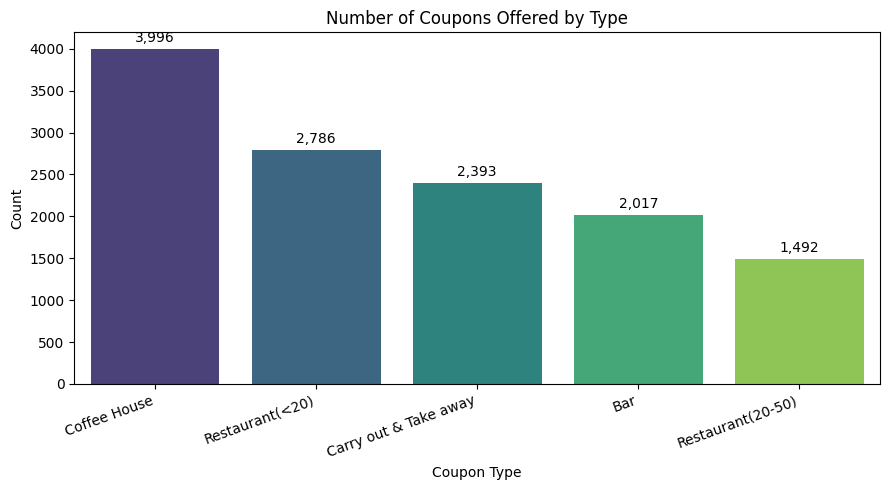

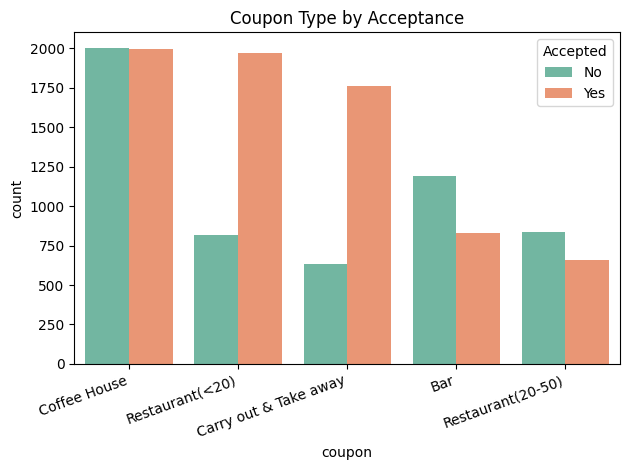

,count
coupon,
Coffee House,3996
Restaurant(<20),2786
Carry out & Take away,2393
Bar,2017
Restaurant(20-50),1492


In [12]:
## Problem 5: Bar plot of the coupon column
coupon_counts = data['coupon'].value_counts()

fig, ax = plt.subplots(figsize=(9, 5))
sns.barplot(x=coupon_counts.index, y=coupon_counts.values,
            hue=coupon_counts.index, palette='viridis', legend=False, ax=ax)

# Put the count on top of each bar
for container in ax.containers:
    ax.bar_label(container, fmt='{:,.0f}', padding=3)

ax.set_title('Number of Coupons Offered by Type')
ax.set_xlabel('Coupon Type')
ax.set_ylabel('Count')
plt.xticks(rotation=20, ha='right')
plt.tight_layout()
plt.show()

ax = sns.countplot(data=data, x='coupon', hue='Y',
                   order=coupon_counts.index, palette='Set2')
ax.legend(title='Accepted', labels=['No', 'Yes'])
ax.set_title('Coupon Type by Acceptance')
plt.xticks(rotation=20, ha='right')
plt.tight_layout()
plt.show()

coupon_counts

6. Use a histogram to visualize the temperature column.

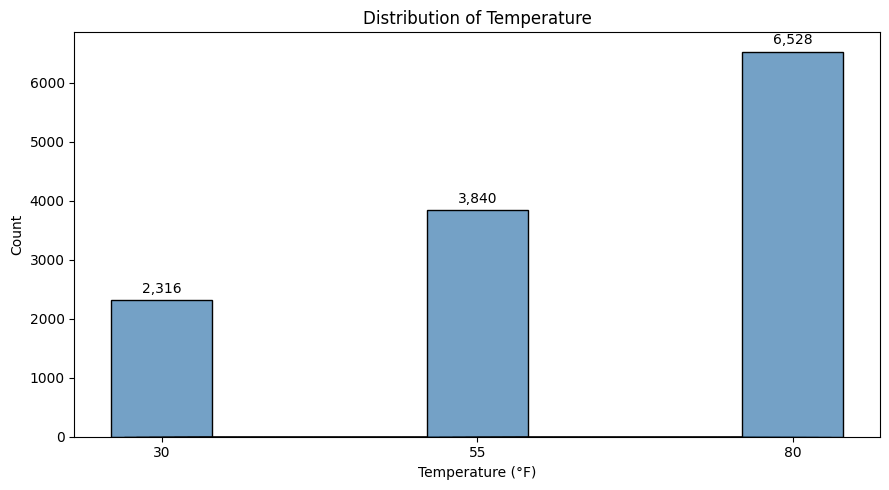

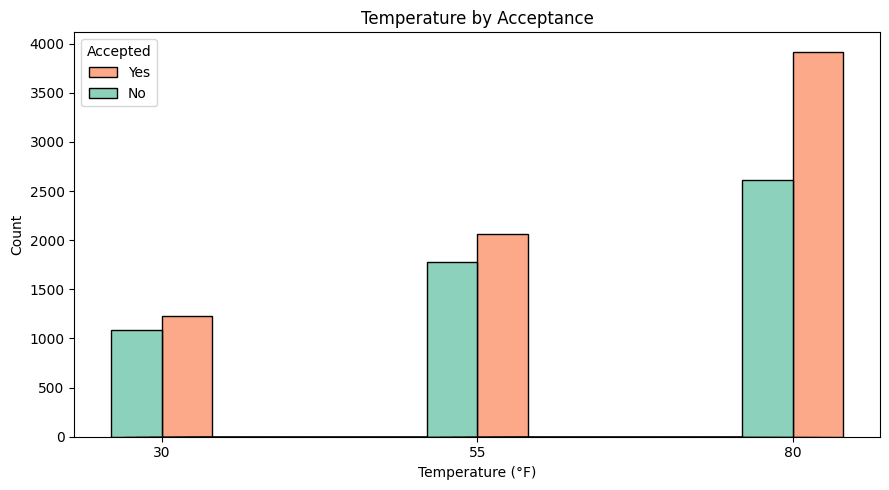

,count,acceptance_rate
temperature,,
30,2316,0.531
55,3840,0.537
80,6528,0.600


In [15]:
## Problem 6: Histogram of the temperature column
# Temperature only takes three values (30, 55, 80), so use discrete bins
# centered on each value instead of the default 10 continuous bins.

fig, ax = plt.subplots(figsize=(9, 5))
sns.histplot(data=data, x='temperature', discrete=True, shrink=8,
             color='steelblue', ax=ax)

# Put the count on top of each bar
for container in ax.containers:
    labels = [f'{v:,.0f}' if v > 0 else '' for v in container.datavalues]
    ax.bar_label(container, labels=labels, padding=3)

ax.set_xticks(sorted(data['temperature'].unique()))
ax.set_title('Distribution of Temperature')
ax.set_xlabel('Temperature (°F)')
ax.set_ylabel('Count')
plt.tight_layout()
plt.show()

# Same histogram, split by whether the coupon was accepted
fig, ax = plt.subplots(figsize=(9, 5))
sns.histplot(data=data, x='temperature', hue='Y', discrete=True, shrink=8,
             multiple='dodge', palette='Set2', ax=ax)
ax.set_xticks(sorted(data['temperature'].unique()))
ax.legend(title='Accepted', labels=['Yes', 'No'])
ax.set_title('Temperature by Acceptance')
ax.set_xlabel('Temperature (°F)')
ax.set_ylabel('Count')
plt.tight_layout()
plt.show()

# Counts and acceptance rate at each temperature
data.groupby('temperature')['Y'].agg(count='size', acceptance_rate='mean').round(3)

**Investigating the Bar Coupons**

Now, we will lead you through an exploration of just the bar related coupons.  

1. Create a new `DataFrame` that contains just the bar coupons.


In [16]:
## Bar Coupons 1: New DataFrame containing only the bar coupons
bar = data[data['coupon'] == 'Bar'].copy()

print(f"Bar coupons: {len(bar):,} of {len(data):,} rows ({len(bar) / len(data):.1%})")
print(f"Columns: {bar.shape[1]}")

bar.head()

Bar coupons: 2,017 of 12,684 rows (15.9%)
Columns: 25


,destination,passanger,weather,temperature,time,coupon,expiration,gender,age,maritalStatus,...,CoffeeHouse,CarryAway,RestaurantLessThan20,Restaurant20To50,toCoupon_GEQ5min,toCoupon_GEQ15min,toCoupon_GEQ25min,direction_same,direction_opp,Y
9,No Urgent Place,Kid(s),Sunny,80,10AM,Bar,1d,Female,21,Unmarried partner,...,never,1~3,4~8,1~3,1,1,0,0,1,0
13,Home,Alone,Sunny,55,6PM,Bar,1d,Female,21,Unmarried partner,...,never,1~3,4~8,1~3,1,0,0,1,0,1
17,Work,Alone,Sunny,55,7AM,Bar,1d,Female,21,Unmarried partner,...,never,1~3,4~8,1~3,1,1,1,0,1,0
24,No Urgent Place,Friend(s),Sunny,80,10AM,Bar,1d,Male,21,Single,...,less1,4~8,4~8,less1,1,0,0,0,1,1
35,Home,Alone,Sunny,55,6PM,Bar,1d,Male,21,Single,...,less1,4~8,4~8,less1,1,0,0,1,0,1


2. What proportion of bar coupons were accepted?


In [17]:
## Bar Coupons 1: New DataFrame containing only the bar coupons
bar = data[data['coupon'] == 'Bar'].copy()

print(f"Bar coupons: {len(bar):,} of {len(data):,} rows ({len(bar) / len(data):.1%})")
print(f"Columns: {bar.shape[1]}\n")

## Bar Coupons 2: Proportion of bar coupons that were accepted
bar_accepted = bar['Y'].sum()
bar_rate = bar['Y'].mean()

print(f"Accepted: {bar_accepted:,} of {len(bar):,}")
print(f"Bar coupon acceptance rate: {bar_rate:.1%}")
print(f"Declined rate:              {1 - bar_rate:.1%}")
print(f"Overall acceptance rate (all coupons): {data['Y'].mean():.1%}")

# Breakdown table
bar['Y'].value_counts(normalize=True).rename({1: 'Accepted', 0: 'Declined'}).round(3)

Bar coupons: 2,017 of 12,684 rows (15.9%)
Columns: 25

Accepted: 827 of 2,017
Bar coupon acceptance rate: 41.0%
Declined rate:              59.0%
Overall acceptance rate (all coupons): 56.8%


,proportion
Y,
Declined,0.59
Accepted,0.41


3. Compare the acceptance rate between those who went to a bar 3 or fewer times a month to those who went more.


3 or fewer    674 of 1,818 accepted (37.1%)
More than 3   153 of   199 accepted (76.9%)


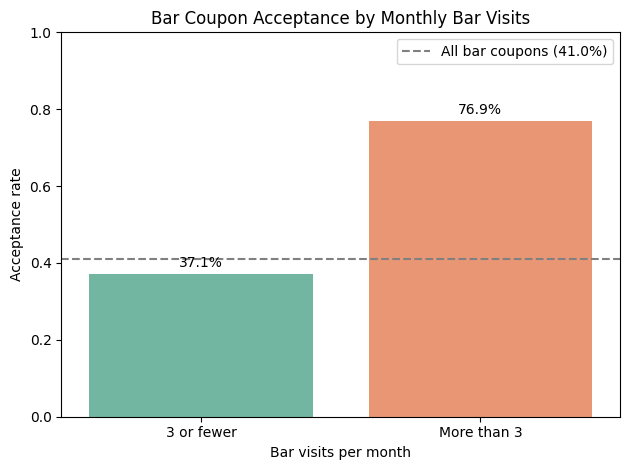

,drivers,accepted,acceptance_rate
bar_freq_group,,,
3 or fewer,1818,674,0.371
More than 3,199,153,0.769


In [18]:
## Bar Coupons 3: Bar visits 3 or fewer times a month vs. more than 3
low_freq = ['never', 'less1', '1~3']   # 3 or fewer times a month
high_freq = ['4~8', 'gt8']            # more than 3 times a month

bar['bar_freq_group'] = np.where(bar['Bar'].isin(low_freq),
                                 '3 or fewer', 'More than 3')

freq_summary = (bar.groupby('bar_freq_group')['Y']
                   .agg(drivers='size', accepted='sum', acceptance_rate='mean'))

for group, row in freq_summary.iterrows():
    print(f"{group:<12} {row['accepted']:>4,.0f} of {row['drivers']:>5,.0f} accepted "
          f"({row['acceptance_rate']:.1%})")

ax = sns.barplot(x=freq_summary.index, y=freq_summary['acceptance_rate'],
                 hue=freq_summary.index, palette='Set2', legend=False)
for container in ax.containers:
    ax.bar_label(container, fmt='{:.1%}', padding=3)
ax.axhline(bar_rate, color='gray', linestyle='--', label=f'All bar coupons ({bar_rate:.1%})')
ax.legend()
ax.set_ylim(0, 1)
ax.set_title('Bar Coupon Acceptance by Monthly Bar Visits')
ax.set_xlabel('Bar visits per month')
ax.set_ylabel('Acceptance rate')
plt.tight_layout()
plt.show()

freq_summary.round(3)

4. Compare the acceptance rate between drivers who go to a bar more than once a month and are over the age of 25 to the all others.  Is there a difference?


Q4 -- Bar more than once a month and over 25 vs. all others:
  Bar >1/month & age >25    292 of   420 accepted (69.5%)
  All others                535 of 1,597 accepted (33.5%)
  Difference: 36.0% points


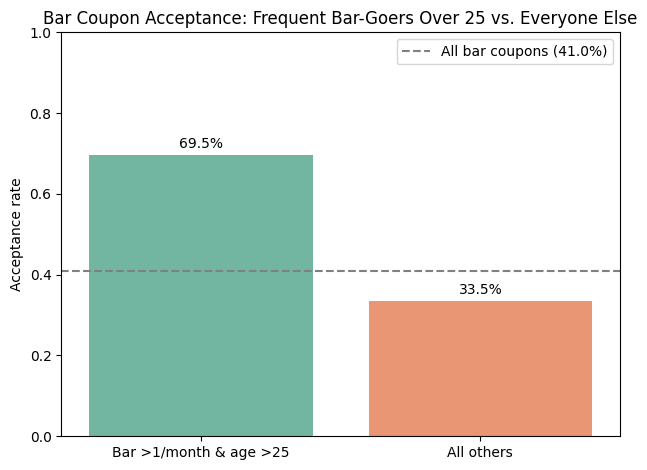

,drivers,accepted,acceptance_rate
q4_group,,,
Bar >1/month & age >25,420,292,0.695
All others,1597,535,0.335


In [19]:
## Bar Coupons 4: Bar more than once a month AND over age 25 vs. all others
# 'More than once a month' = 1~3, 4~8, gt8 (excludes never and less1)
more_than_once = ['1~3', '4~8', 'gt8']

# Age is stored as text ('below21', '21', ..., '50plus'); convert to numbers
age_num = bar['age'].replace({'below21': 20, '50plus': 50}).astype(int)

target = bar['Bar'].isin(more_than_once) & (age_num > 25)
bar['q4_group'] = np.where(target, 'Bar >1/month & age >25', 'All others')

q4_summary = (bar.groupby('q4_group')['Y']
                 .agg(drivers='size', accepted='sum', acceptance_rate='mean')
                 .loc[['Bar >1/month & age >25', 'All others']])

print("Q4 -- Bar more than once a month and over 25 vs. all others:")
for group, row in q4_summary.iterrows():
    print(f"  {group:<24} {row['accepted']:>4,.0f} of {row['drivers']:>5,.0f} accepted "
          f"({row['acceptance_rate']:.1%})")

diff = q4_summary['acceptance_rate'].iloc[0] - q4_summary['acceptance_rate'].iloc[1]
print(f"  Difference: {diff:.1%} points")

# Plot
ax = sns.barplot(x=q4_summary.index, y=q4_summary['acceptance_rate'],
                 hue=q4_summary.index, palette='Set2', legend=False)
for container in ax.containers:
    ax.bar_label(container, fmt='{:.1%}', padding=3)
ax.axhline(bar_rate, color='gray', linestyle='--', label=f'All bar coupons ({bar_rate:.1%})')
ax.legend()
ax.set_ylim(0, 1)
ax.set_title('Bar Coupon Acceptance: Frequent Bar-Goers Over 25 vs. Everyone Else')
ax.set_xlabel('')
ax.set_ylabel('Acceptance rate')
plt.tight_layout()
plt.show()

q4_summary.round(3)

5. Use the same process to compare the acceptance rate between drivers who go to bars more than once a month and had passengers that were not a kid and had occupations other than farming, fishing, or forestry.



Q5 -- Bar more than once a month, no kid passengers, not farming/fishing/forestry:
  Bar >1/month, no kids, not FFF    393 of   551 accepted (71.3%)
  All others                        434 of 1,466 accepted (29.6%)
  Difference: 41.7% points


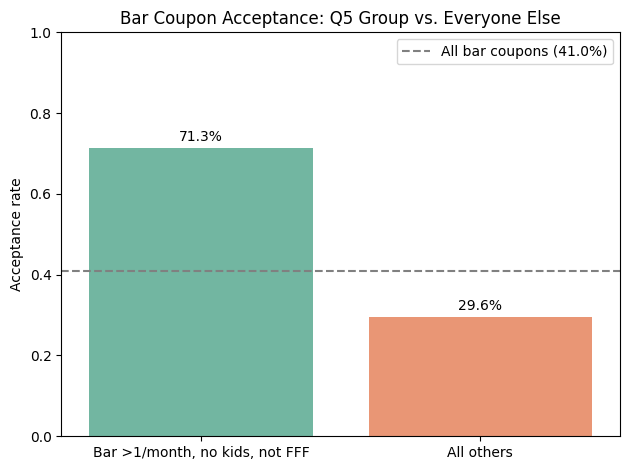

,drivers,accepted,acceptance_rate
q5_group,,,
"Bar >1/month, no kids, not FFF",551,393,0.713
All others,1466,434,0.296


In [20]:
## Bar Coupons 5: Bar more than once a month, passengers not a kid,
##                occupation not farming/fishing/forestry vs. all others
# Note: the passenger column is misspelled 'passanger' in the dataset
target5 = (bar['Bar'].isin(more_than_once)
           & (bar['passanger'] != 'Kid(s)')
           & (bar['occupation'] != 'Farming Fishing & Forestry'))
bar['q5_group'] = np.where(target5, 'Bar >1/month, no kids, not FFF', 'All others')

q5_summary = (bar.groupby('q5_group')['Y']
                 .agg(drivers='size', accepted='sum', acceptance_rate='mean')
                 .loc[['Bar >1/month, no kids, not FFF', 'All others']])

print("\nQ5 -- Bar more than once a month, no kid passengers, not farming/fishing/forestry:")
for group, row in q5_summary.iterrows():
    print(f"  {group:<32} {row['accepted']:>4,.0f} of {row['drivers']:>5,.0f} accepted "
          f"({row['acceptance_rate']:.1%})")

diff5 = q5_summary['acceptance_rate'].iloc[0] - q5_summary['acceptance_rate'].iloc[1]
print(f"  Difference: {diff5:.1%} points")

# Plot
ax = sns.barplot(x=q5_summary.index, y=q5_summary['acceptance_rate'],
                 hue=q5_summary.index, palette='Set2', legend=False)
for container in ax.containers:
    ax.bar_label(container, fmt='{:.1%}', padding=3)
ax.axhline(bar_rate, color='gray', linestyle='--', label=f'All bar coupons ({bar_rate:.1%})')
ax.legend()
ax.set_ylim(0, 1)
ax.set_title('Bar Coupon Acceptance: Q5 Group vs. Everyone Else')
ax.set_xlabel('')
ax.set_ylabel('Acceptance rate')
plt.tight_layout()
plt.show()

q5_summary.round(3)

6. Compare the acceptance rates between those drivers who:

- go to bars more than once a month, had passengers that were not a kid, and were not widowed *OR*
- go to bars more than once a month and are under the age of 30 *OR*
- go to cheap restaurants more than 4 times a month and income is less than 50K.




Q6 -- Acceptance by condition:
  A: Bar >1/mo, no kids, not widowed    393 of   551 accepted (71.3%)
  B: Bar >1/mo, under 30                249 of   345 accepted (72.2%)
  C: Cheap rest. >4/mo, income <$50K    156 of   344 accepted (45.3%)
  Any of A, B, or C                     457 of   776 accepted (58.9%)
  None of A, B, or C                    370 of 1,241 accepted (29.8%)
  Difference (any vs. none): 29.1% points


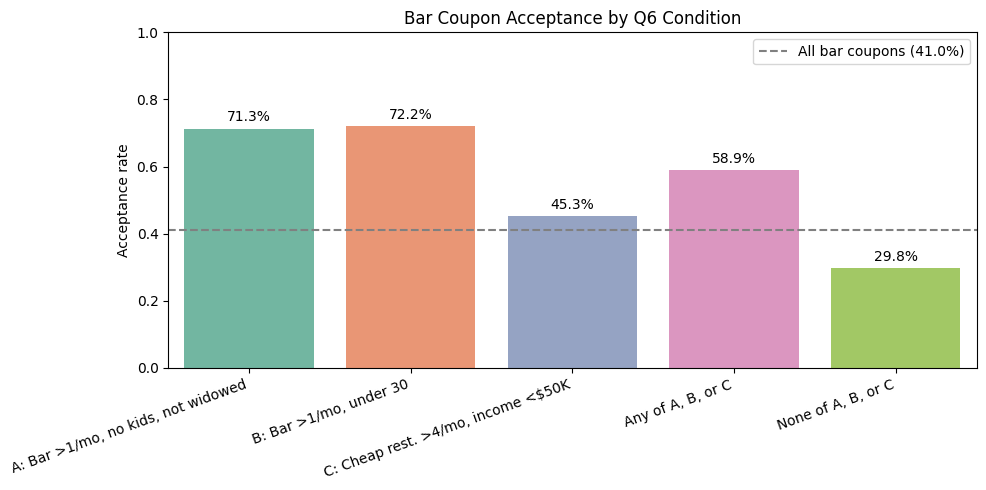

,drivers,accepted,acceptance_rate
"A: Bar >1/mo, no kids, not widowed",551,393,0.713
"B: Bar >1/mo, under 30",345,249,0.722
"C: Cheap rest. >4/mo, income <$50K",344,156,0.453
"Any of A, B, or C",776,457,0.589
"None of A, B, or C",1241,370,0.298


In [21]:
## Bar Coupons 6: Compare acceptance for drivers who
##   (A) go to bars >1/month, had passengers that were not a kid, and were not widowed, OR
##   (B) go to bars >1/month and are under the age of 30, OR
##   (C) go to cheap restaurants >4 times a month and income is less than $50K
cheap_more_than_4 = ['4~8', 'gt8']
income_under_50k = ['Less than $12500', '$12500 - $24999',
                    '$25000 - $37499', '$37500 - $49999']

cond_a = (bar['Bar'].isin(more_than_once)
          & (bar['passanger'] != 'Kid(s)')
          & (bar['maritalStatus'] != 'Widowed'))
cond_b = bar['Bar'].isin(more_than_once) & (age_num < 30)
cond_c = (bar['RestaurantLessThan20'].isin(cheap_more_than_4)
          & bar['income'].isin(income_under_50k))
cond_any = cond_a | cond_b | cond_c

q6_groups = {
    'A: Bar >1/mo, no kids, not widowed': cond_a,
    'B: Bar >1/mo, under 30':             cond_b,
    'C: Cheap rest. >4/mo, income <$50K': cond_c,
    'Any of A, B, or C':                  cond_any,
    'None of A, B, or C':                 ~cond_any,
}

q6_summary = pd.DataFrame({
    name: {'drivers': mask.sum(),
           'accepted': bar.loc[mask, 'Y'].sum(),
           'acceptance_rate': bar.loc[mask, 'Y'].mean()}
    for name, mask in q6_groups.items()
}).T

print("\nQ6 -- Acceptance by condition:")
for group, row in q6_summary.iterrows():
    print(f"  {group:<36} {row['accepted']:>4,.0f} of {row['drivers']:>5,.0f} accepted "
          f"({row['acceptance_rate']:.1%})")

diff6 = (q6_summary.loc['Any of A, B, or C', 'acceptance_rate']
         - q6_summary.loc['None of A, B, or C', 'acceptance_rate'])
print(f"  Difference (any vs. none): {diff6:.1%} points")

# Plot
fig, ax = plt.subplots(figsize=(10, 5))
sns.barplot(x=q6_summary.index, y=q6_summary['acceptance_rate'].astype(float),
            hue=q6_summary.index, palette='Set2', legend=False, ax=ax)
for container in ax.containers:
    ax.bar_label(container, fmt='{:.1%}', padding=3)
ax.axhline(bar_rate, color='gray', linestyle='--', label=f'All bar coupons ({bar_rate:.1%})')
ax.legend()
ax.set_ylim(0, 1)
ax.set_title('Bar Coupon Acceptance by Q6 Condition')
ax.set_xlabel('')
ax.set_ylabel('Acceptance rate')
plt.xticks(rotation=20, ha='right')
plt.tight_layout()
plt.show()

q6_summary.astype({'drivers': int, 'accepted': int}).round(3)

7.  Based on these observations, what do you hypothesize about drivers who accepted the bar coupons?

**7. Hypothesis about drivers who accepted bar coupons**

Bar coupons are the least accepted coupon type: only about 41.0% were accepted (827 of 2,017),
compared with 56.8% across all coupons. But acceptance is far from uniform. Every analysis above
points to the same conclusion:

**Hypothesis: Whether a driver accepts a bar coupon depends mainly on whether they already go to
bars regularly (at least once a month). Situations where a bar visit is impractical, mainly having
a child in the car, lower acceptance further. Demographic and lifestyle traits unrelated to
bar-going add little.**

Supporting evidence:

- **Bar-going habit is the strongest signal.** Drivers who go to a bar more than 3 times a month
  accepted about 76.9% of bar coupons, versus 37.1% for those who go 3 or fewer times (Q3). Every
  group built on bar visits more than once a month lands around 70%: 69.5% (Q4), 71.3% (Q5),
  and about 71–72% (Q6 conditions A and B). That is nearly twice the overall bar rate.
- **Passengers matter.** Removing trips with kid passengers produces one of the cleanest splits:
  71.3% vs. 29.6% (Q5). A driver with children in the car is unlikely to stop at a bar,
  whatever their habits.
- **Age adds a little, not a lot.** Among regular bar-goers, drivers under 30 accepted about 72%
  (Q6-B), slightly more than those over 25 at 69.5% (Q4). Younger drivers may be a bit more
  receptive, but bar-going habit explains most of the difference.
- **Unrelated traits are weak predictors.** Excluding farming/fishing/forestry occupations (Q5) or
  widowed drivers (Q6-A) barely changes the results, because those groups are tiny. Frequent
  cheap-restaurant visits combined with income under $50K (Q6-C) gives only about 45%, just above
  the 41.0% baseline. Eating out often on a budget does not translate into accepting bar coupons.

**Implication:** Bar coupons would be most effective if targeted at drivers who already go to bars
at least monthly, especially younger drivers without children in the car. Sending them to
non-bar-goers or to drivers with kids mostly produces rejections.

*Caveat:* These are comparisons of acceptance rates in survey responses, not causal tests.
Some groups overlap or are small, so the hypothesis should be confirmed with statistical testing
or a model that accounts for several factors at once.

### Independent Investigation

Using the bar coupon example as motivation, you are to explore one of the other coupon groups and try to determine the characteristics of passengers who accept the coupons.  

In [23]:
## Independent Investigation: Coffee House coupons
coffee = data[data['coupon'] == 'Coffee House'].copy()
coffee_rate = coffee['Y'].mean()

print(f"Coffee House coupons: {len(coffee):,} of {len(data):,} rows ({len(coffee) / len(data):.1%})")
print(f"Accepted: {coffee['Y'].sum():,} of {len(coffee):,}")
print(f"Coffee House acceptance rate: {coffee_rate:.1%}")
print(f"Overall acceptance rate (all coupons): {data['Y'].mean():.1%}")

# Readable distance column (toCoupon_GEQ5min is 1 for every row, so it is not informative)
coffee['distance'] = np.select(
    [coffee['toCoupon_GEQ25min'] == 1, coffee['toCoupon_GEQ15min'] == 1],
    ['25+ min', '15-25 min'], default='Under 15 min')

# Helper: acceptance rate by one column, as a table and a labeled bar chart
def acceptance_by(df, col, order=None, title=None, ax=None, baseline=None):
    summary = df.groupby(col)['Y'].agg(drivers='size', acceptance_rate='mean')
    if order is not None:
        summary = summary.reindex([o for o in order if o in summary.index])
    ax = ax or plt.gca()
    sns.barplot(x=summary.index.astype(str), y=summary['acceptance_rate'],
                hue=summary.index.astype(str), palette='Set2', legend=False, ax=ax)
    for container in ax.containers:
        ax.bar_label(container, fmt='{:.0%}', padding=3, fontsize=9)
    if baseline is not None:
        ax.axhline(baseline, color='gray', linestyle='--')
    ax.set_ylim(0, 1)
    ax.set_title(title or col)
    ax.set_xlabel('')
    ax.set_ylabel('Acceptance rate')
    ax.tick_params(axis='x', rotation=30)
    return summary

coffee['Y'].value_counts(normalize=True).rename({1: 'Accepted', 0: 'Declined'}).round(3)

Coffee House coupons: 3,996 of 12,684 rows (31.5%)
Accepted: 1,995 of 3,996
Coffee House acceptance rate: 49.9%
Overall acceptance rate (all coupons): 56.8%


,proportion
Y,
Declined,0.501
Accepted,0.499


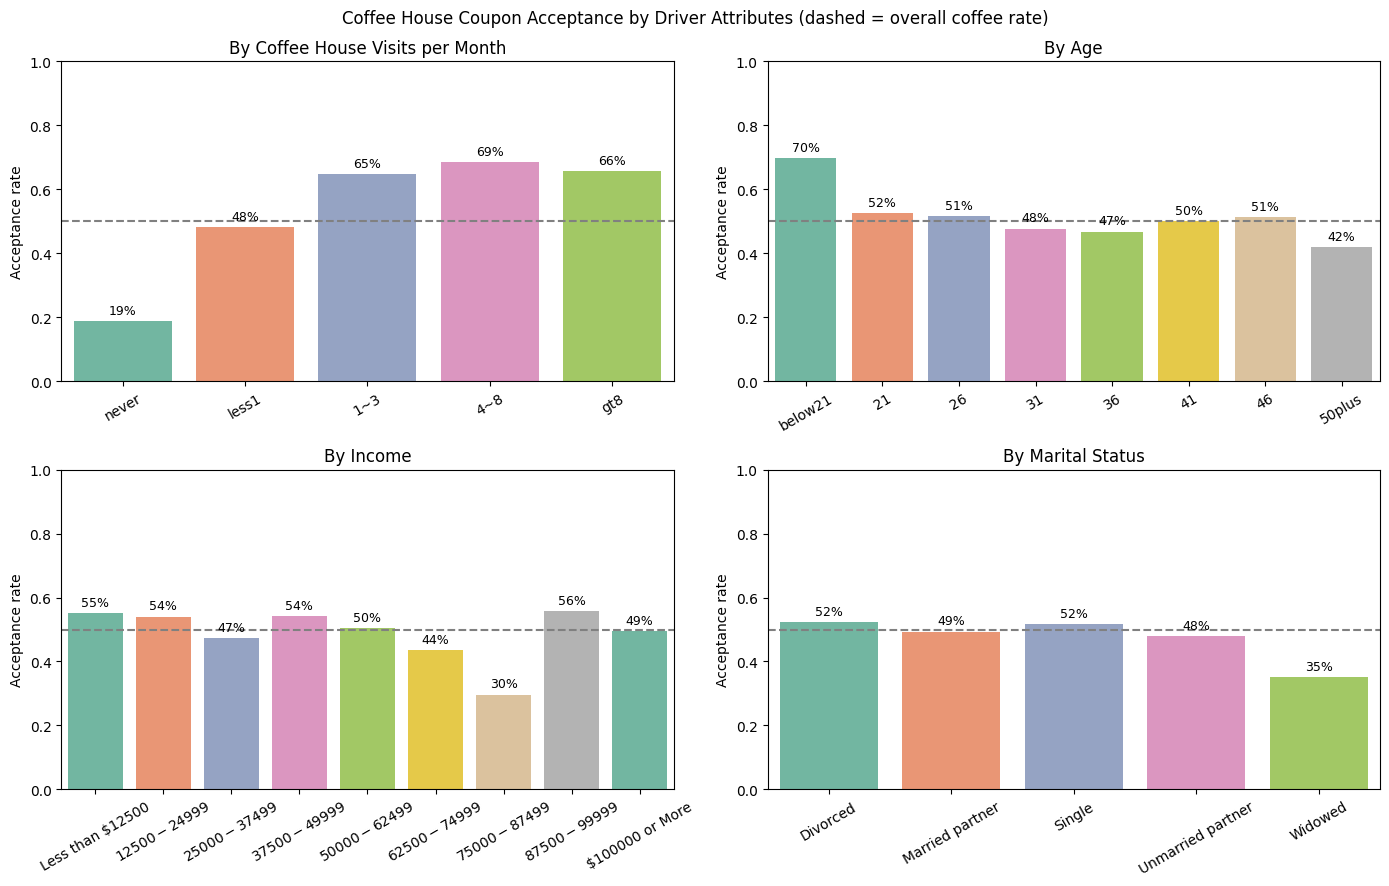


CoffeeHouse visits/month:
             drivers  acceptance_rate
CoffeeHouse                          
never            927            0.189
less1           1147            0.480
1~3             1042            0.648
4~8              538            0.686
gt8              342            0.658

Age:
         drivers  acceptance_rate
age                              
below21      155            0.697
21           883            0.524
26           843            0.515
31           623            0.477
36           402            0.468
41           325            0.502
46           220            0.514
50plus       545            0.420

Income:
                  drivers  acceptance_rate
income                                    
Less than $12500      308            0.552
$12500 - $24999       594            0.540
$25000 - $37499       640            0.473
$37500 - $49999       590            0.542
$50000 - $62499       548            0.504
$62500 - $74999       275            0.436
$75000 -

In [24]:
## Who accepts? Driver characteristics
freq_order = ['never', 'less1', '1~3', '4~8', 'gt8']
age_order = ['below21', '21', '26', '31', '36', '41', '46', '50plus']
income_order = ['Less than $12500', '$12500 - $24999', '$25000 - $37499', '$37500 - $49999',
                '$50000 - $62499', '$62500 - $74999', '$75000 - $87499', '$87500 - $99999',
                '$100000 or More']

fig, axes = plt.subplots(2, 2, figsize=(14, 9))
user_tables = {
    'CoffeeHouse visits/month': acceptance_by(coffee, 'CoffeeHouse', freq_order,
                                              'By Coffee House Visits per Month', axes[0, 0], coffee_rate),
    'Age':     acceptance_by(coffee, 'age', age_order, 'By Age', axes[0, 1], coffee_rate),
    'Income':  acceptance_by(coffee, 'income', income_order, 'By Income', axes[1, 0], coffee_rate),
    'Marital': acceptance_by(coffee, 'maritalStatus', None, 'By Marital Status', axes[1, 1], coffee_rate),
}
fig.suptitle('Coffee House Coupon Acceptance by Driver Attributes (dashed = overall coffee rate)')
plt.tight_layout()
plt.show()

for name, table in user_tables.items():
    print(f"\n{name}:")
    print(table.round(3).to_string())

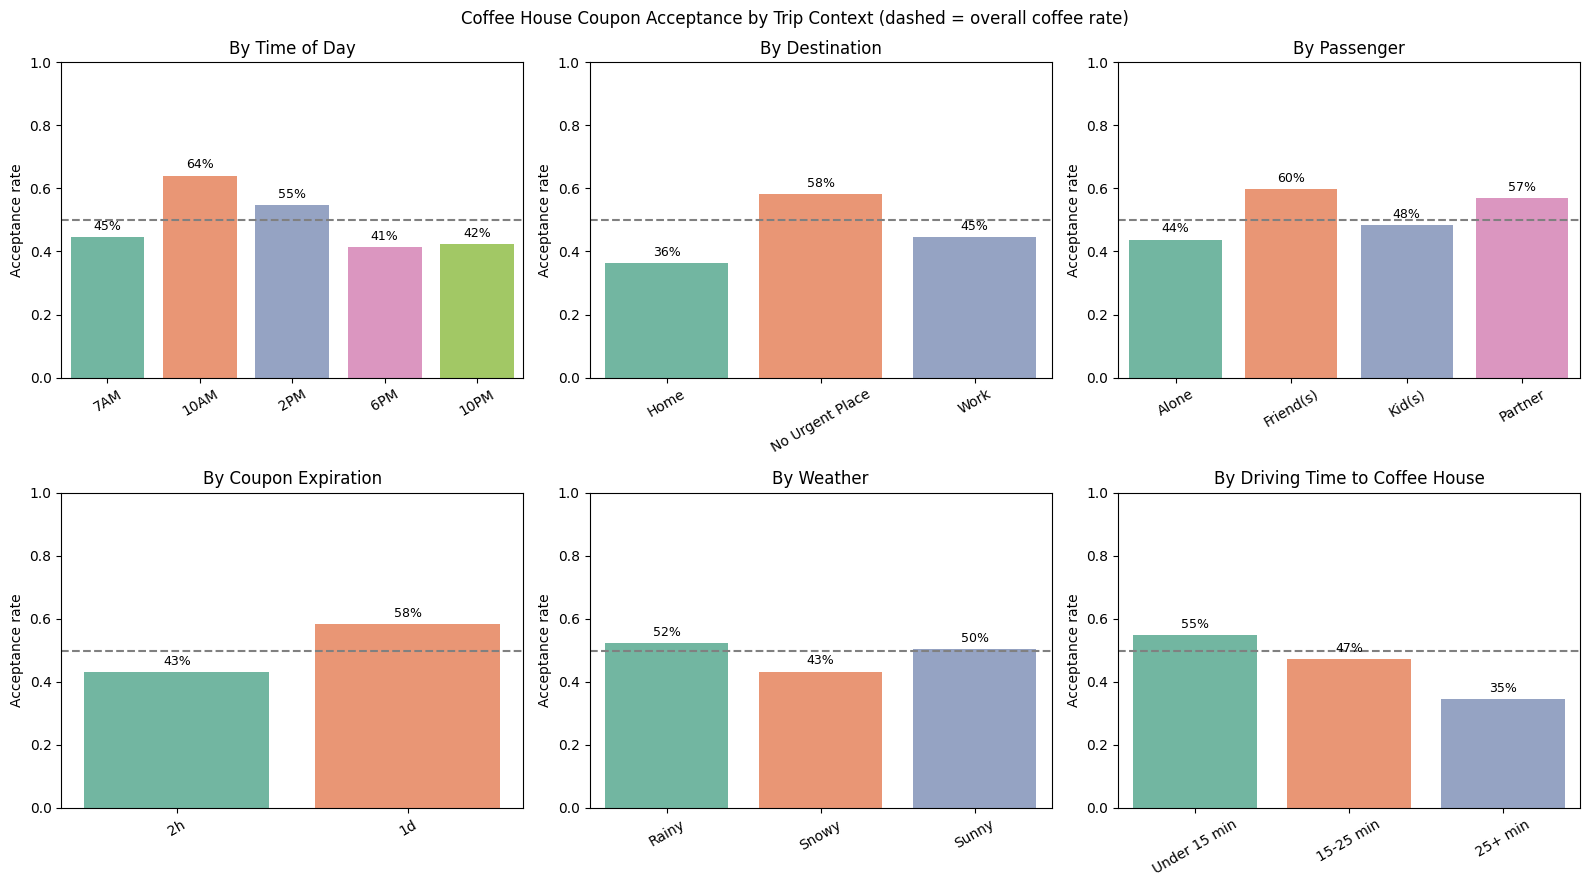


Time:
      drivers  acceptance_rate
time                          
7AM       913            0.446
10AM      899            0.641
2PM       794            0.548
6PM      1093            0.413
10PM      297            0.424

Destination:
                 drivers  acceptance_rate
destination                              
Home                 928            0.362
No Urgent Place     2155            0.581
Work                 913            0.446

Passenger:
           drivers  acceptance_rate
passanger                          
Alone         2256            0.438
Friend(s)     1228            0.597
Kid(s)         207            0.483
Partner        305            0.570

Expiration:
            drivers  acceptance_rate
expiration                          
2h             2227            0.432
1d             1769            0.584

Weather:
         drivers  acceptance_rate
weather                          
Rainy        226            0.522
Snowy        303            0.432
Sunny       3467 

In [25]:
## When does it get accepted? Trip and coupon context
time_order = ['7AM', '10AM', '2PM', '6PM', '10PM']

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
context_tables = {
    'Time':        acceptance_by(coffee, 'time', time_order, 'By Time of Day', axes[0, 0], coffee_rate),
    'Destination': acceptance_by(coffee, 'destination', None, 'By Destination', axes[0, 1], coffee_rate),
    'Passenger':   acceptance_by(coffee, 'passanger', None, 'By Passenger', axes[0, 2], coffee_rate),
    'Expiration':  acceptance_by(coffee, 'expiration', ['2h', '1d'], 'By Coupon Expiration', axes[1, 0], coffee_rate),
    'Weather':     acceptance_by(coffee, 'weather', None, 'By Weather', axes[1, 1], coffee_rate),
    'Distance':    acceptance_by(coffee, 'distance', ['Under 15 min', '15-25 min', '25+ min'],
                                 'By Driving Time to Coffee House', axes[1, 2], coffee_rate),
}
fig.suptitle('Coffee House Coupon Acceptance by Trip Context (dashed = overall coffee rate)')
plt.tight_layout()
plt.show()

for name, table in context_tables.items():
    print(f"\n{name}:")
    print(table.round(3).to_string())

  Regular + no urgent place, 10AM/2PM              628.0 of 811.0 accepted (77.4%)
  Regular + no urgent place, 10AM/2PM, 1d coupon   302.0 of 371.0 accepted (81.4%)
  Regular, any context                             1,269.0 of 1,922.0 accepted (66.0%)
  Not regular (never / less than 1x)               726.0 of 2,074.0 accepted (35.0%)
  Never goes to coffee houses                      175.0 of 927.0 accepted (18.9%)


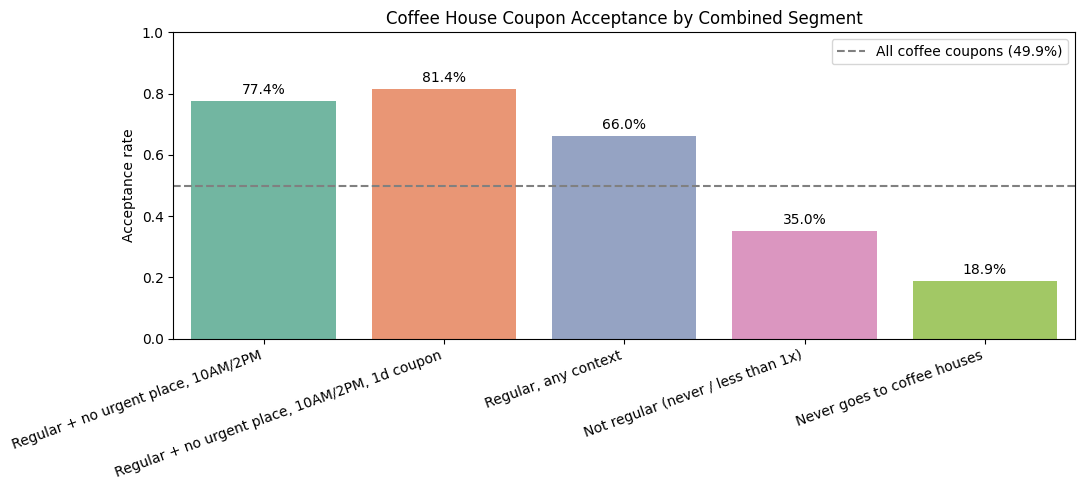

,drivers,accepted,acceptance_rate
"Regular + no urgent place, 10AM/2PM",811,628,0.774
"Regular + no urgent place, 10AM/2PM, 1d coupon",371,302,0.814
"Regular, any context",1922,1269,0.660
Not regular (never / less than 1x),2074,726,0.350
Never goes to coffee houses,927,175,0.189


In [26]:
## Combining the strongest factors
regular = coffee['CoffeeHouse'].isin(['1~3', '4~8', 'gt8'])          # visits at least once a month
good_context = (coffee['destination'] == 'No Urgent Place') & coffee['time'].isin(['10AM', '2PM'])
long_expiry = coffee['expiration'] == '1d'

segments = {
    'Regular + no urgent place, 10AM/2PM':          regular & good_context,
    'Regular + no urgent place, 10AM/2PM, 1d coupon': regular & good_context & long_expiry,
    'Regular, any context':                         regular,
    'Not regular (never / less than 1x)':           ~regular,
    'Never goes to coffee houses':                  coffee['CoffeeHouse'] == 'never',
}

seg_summary = pd.DataFrame({
    name: {'drivers': mask.sum(),
           'accepted': coffee.loc[mask, 'Y'].sum(),
           'acceptance_rate': coffee.loc[mask, 'Y'].mean()}
    for name, mask in segments.items()
}).T.astype({'drivers': int, 'accepted': int})

for group, row in seg_summary.iterrows():
    print(f"  {group:<48} {row['accepted']:>5,} of {row['drivers']:>5,} accepted "
          f"({row['acceptance_rate']:.1%})")

fig, ax = plt.subplots(figsize=(11, 5))
sns.barplot(x=seg_summary.index, y=seg_summary['acceptance_rate'].astype(float),
            hue=seg_summary.index, palette='Set2', legend=False, ax=ax)
for container in ax.containers:
    ax.bar_label(container, fmt='{:.1%}', padding=3)
ax.axhline(coffee_rate, color='gray', linestyle='--', label=f'All coffee coupons ({coffee_rate:.1%})')
ax.legend()
ax.set_ylim(0, 1)
ax.set_title('Coffee House Coupon Acceptance by Combined Segment')
ax.set_xlabel('')
ax.set_ylabel('Acceptance rate')
plt.xticks(rotation=20, ha='right')
plt.tight_layout()
plt.show()

seg_summary.round(3)

**Findings: Who accepts Coffee House coupons?**

Coffee House coupons are the most common coupon type (3,996 of 12,684), and acceptance is close to
a coin flip, about 50%, below the 56.8% rate for all coupons. Splitting by driver and trip
characteristics shows that acceptance depends heavily on two things: **the driver's existing coffee
habit** and **whether the trip leaves room for a stop**.

**Driver characteristics**
- **Coffee habit is the strongest signal, as bar habit was for bar coupons.** Drivers who never go
  to coffee houses rarely accept (roughly 1 in 5). Drivers who go at least once a month accept
  about two-thirds of the time.
- **Age and income have smaller effects.** Younger drivers (under 26) accept somewhat more often
  than older drivers. Income shows no consistent upward or downward trend.

**Trip and coupon context**
- **Time of day matters.** Mid-morning (10AM) is the peak, 2PM is above average, and evening
  (6PM, 10PM) is lowest. Coffee is a daytime purchase.
- **Destination matters.** Drivers with no urgent destination accept far more often than those
  heading home or to work.
- **Company matters.** Drivers with friends or a partner accept more often than drivers alone.
- **Longer coupons work better.** One-day coupons are accepted noticeably more often than 2-hour
  coupons, because the driver can use them later.
- **Weather and distance play a smaller role.** Shorter driving times help a little.

**Combined:** Regular coffee drivers on a non-urgent daytime trip accept at well above the average
rate. Adding a 1-day expiration raises it further. Drivers who never visit coffee houses accept
rarely, regardless of context.

**Hypothesis:** Coffee House coupon acceptors are mainly people who already drink coffee out at
least once a month. They accept most when they are on a flexible, non-urgent trip during the day,
often with friends or a partner, and when the coupon gives them time to use it. Targeting these
drivers in these situations, and avoiding evening sends and non-coffee drinkers, would raise
acceptance well above 50%.

*Caveat:* These are acceptance-rate comparisons from survey responses, not causal tests. Some
factors overlap (for example, "no urgent place" trips happen more often with friends and at
midday), so a multivariable model would be needed to separate their effects.